# Modelo barotrópico con difusión de potencia: estudio gráfico

Este notebook reúne el apartado gráfico desarrollado previamente para

\[
p=\omega\rho,
\qquad
Q=\alpha\rho^\beta,
\qquad
3H^2=\rho+\alpha\rho^\beta.
\]

Contiene el barrido paramétrico, el análisis mediante Lambert \(W\), las
curvas de \(\rho(a)\) y la reconstrucción paramétrica de \(\rho(t)\).

> Este notebook conserva el enfoque gráfico anterior. El nuevo solucionador
> temporal directo y sus validaciones se encuentran en el notebook
> `02b_modelo_barotropico_difusion_solucion_numerica.ipynb`.


## 1. Configuración

Importaciones, detección de la raíz del proyecto y carga del modelo.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
from pathlib import Path

current_path = Path.cwd()

if (current_path / "src").exists():
    PROJECT_ROOT = current_path
elif (current_path.parent / "src").exists():
    PROJECT_ROOT = current_path.parent
else:
    raise FileNotFoundError("No se encontró la carpeta src.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

from src.models import (
    BarotropicPowerDiffusionParams,
    BarotropicPowerDiffusionModel,
)

from scipy.integrate import solve_ivp


Project root: /Users/macbook/Usach/TesisxD/cosmo_singularities


## 2. Barrido del espacio de parámetros

Construcción del conjunto de combinaciones \((\omega,\alpha,\beta)\) y selección de soluciones válidas.

In [2]:
a_values = np.logspace(0, 3, 500)  # a desde 1 hasta 1000
a_max = a_values[-1]

In [3]:
omega_values = np.linspace(-1.5, -1.01, 20)
alpha_values = np.linspace(0.0, 0.1, 15)
beta_values = np.linspace(0.2, 3.0, 25)

rho0 = 1.0
a0 = 1.0

In [4]:
records = []

for omega in omega_values:
    for alpha in alpha_values:
        for beta in beta_values:
            try:
                params = BarotropicPowerDiffusionParams(
                    omega=omega,
                    alpha=alpha,
                    beta=beta,
                    rho0=rho0,
                    a0=a0,
                )

                model = BarotropicPowerDiffusionModel(params)

                rho_values = model.rho_of_a(a_values)

                record = {
                    "omega": omega,
                    "alpha": alpha,
                    "beta": beta,
                    "rho0": rho0,
                    "a0": a0,
                    "a_max": a_max,
                    "rho_initial": rho_values[0],
                    "rho_final": rho_values[-1],
                    "rho_min": np.min(rho_values),
                    "rho_max": np.max(rho_values),
                    "rho_growth_factor": rho_values[-1] / rho_values[0],
                    "valid_solution": True,
                    "error_message": "",
                }

            except Exception as e:
                record = {
                    "omega": omega,
                    "alpha": alpha,
                    "beta": beta,
                    "rho0": rho0,
                    "a0": a0,
                    "a_max": a_max,
                    "rho_initial": np.nan,
                    "rho_final": np.nan,
                    "rho_min": np.nan,
                    "rho_max": np.nan,
                    "rho_growth_factor": np.nan,
                    "valid_solution": False,
                    "error_message": str(e),
                }

            records.append(record)

df_params = pd.DataFrame(records)

df_params.head()

,omega,alpha,beta,rho0,a0,a_max,rho_initial,rho_final,rho_min,rho_max,rho_growth_factor,valid_solution,error_message
0,-1.5,0.0,0.200000,1.0,1.0,1000.0,1.0,31622.776602,1.0,31622.776602,31622.776602,True,
1,-1.5,0.0,0.316667,1.0,1.0,1000.0,1.0,31622.776602,1.0,31622.776602,31622.776602,True,
2,-1.5,0.0,0.433333,1.0,1.0,1000.0,1.0,31622.776602,1.0,31622.776602,31622.776602,True,
3,-1.5,0.0,0.550000,1.0,1.0,1000.0,1.0,31622.776602,1.0,31622.776602,31622.776602,True,
4,-1.5,0.0,0.666667,1.0,1.0,1000.0,1.0,31622.776602,1.0,31622.776602,31622.776602,True,


In [5]:
df_params["valid_solution"].value_counts()

valid_solution
True    7500
Name: count, dtype: int64

In [6]:
df_valid = df_params[df_params["valid_solution"]].copy()
df_valid.describe()

,omega,alpha,beta,rho0,a0,a_max,rho_initial,rho_final,rho_min,rho_max,rho_growth_factor
count,7500.000000,7500.000000,7500.000000,7500.0,7500.0,7500.0,7.500000e+03,7500.000000,7.500000e+03,7500.000000,7500.000000
mean,-1.255000,0.050000,1.600000,1.0,1.0,1000.0,1.000000e+00,1398.889069,1.000000e+00,1398.889069,1398.889069
std,0.148719,0.030863,0.841351,0.0,0.0,0.0,1.084050e-15,4668.222613,1.084050e-15,4668.222613,4668.222613
min,-1.500000,0.000000,0.200000,1.0,1.0,1000.0,1.000000e+00,1.165768,1.000000e+00,1.165768,1.165768
25%,-1.377500,0.021429,0.900000,1.0,1.0,1000.0,1.000000e+00,6.539453,1.000000e+00,6.539453,6.539453
50%,-1.255000,0.050000,1.600000,1.0,1.0,1000.0,1.000000e+00,21.962684,1.000000e+00,21.962684,21.962684
75%,-1.132500,0.078571,2.300000,1.0,1.0,1000.0,1.000000e+00,218.167491,1.000000e+00,218.167491,218.167491
max,-1.010000,0.100000,3.000000,1.0,1.0,1000.0,1.000000e+00,31622.776602,1.000000e+00,31622.776602,31622.776602


## 3. Dependencia con el parámetro de difusión

Curvas para \(\alpha\geq0\) y estudio del dominio real de Lambert \(W\) cuando \(\alpha<0\).

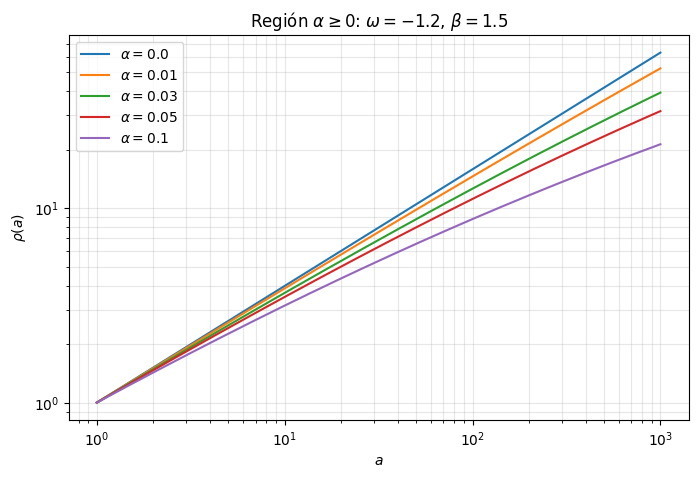

In [9]:
alpha_values_positive = [0.0, 0.01, 0.03, 0.05, 0.1]

omega_fixed = -1.2
beta_fixed = 1.5

plt.figure(figsize=(8, 5))

for alpha in alpha_values_positive:
    params = BarotropicPowerDiffusionParams(
        omega=omega_fixed,
        alpha=alpha,
        beta=beta_fixed,
        rho0=1.0,
        a0=1.0,
    )

    model = BarotropicPowerDiffusionModel(params)
    rho_values = model.rho_of_a(a_values)

    plt.plot(
        a_values,
        rho_values,
        label=rf"$\alpha={alpha}$",
    )

plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"$a$")
plt.ylabel(r"$\rho(a)$")
plt.title(
    rf"Región $\alpha \geq 0$: $\omega={omega_fixed}$, $\beta={beta_fixed}$"
)
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

No se pudo calcular alpha=-0.9: Lambert W devolvió valores complejos no despreciables. Revisa la rama elegida o el rango de a.
No se pudo calcular alpha=-0.7: Lambert W devolvió valores complejos no despreciables. Revisa la rama elegida o el rango de a.
No se pudo calcular alpha=-0.5: Lambert W devolvió valores complejos no despreciables. Revisa la rama elegida o el rango de a.
No se pudo calcular alpha=-0.3: Lambert W devolvió valores complejos no despreciables. Revisa la rama elegida o el rango de a.
No se pudo calcular alpha=-0.1: Lambert W devolvió valores complejos no despreciables. Revisa la rama elegida o el rango de a.


/var/folders/7v/mpqjvkxx00lf3_k_1wpn9jsw0000gn/T/ipykernel_2199/2027229017.py:37: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


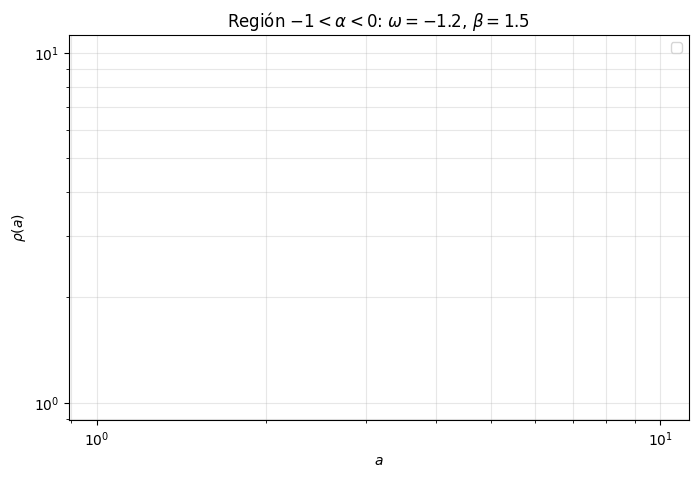

In [10]:
alpha_values_negative = [-0.9, -0.7, -0.5, -0.3, -0.1]

omega_fixed = -1.2
beta_fixed = 1.5

plt.figure(figsize=(8, 5))

for alpha in alpha_values_negative:
    try:
        params = BarotropicPowerDiffusionParams(
            omega=omega_fixed,
            alpha=alpha,
            beta=beta_fixed,
            rho0=1.0,
            a0=1.0,
        )

        model = BarotropicPowerDiffusionModel(params)
        rho_values = model.rho_of_a(a_values)

        plt.plot(
            a_values,
            rho_values,
            label=rf"$\alpha={alpha}$",
        )

    except Exception as e:
        print(f"No se pudo calcular alpha={alpha}: {e}")

plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"$a$")
plt.ylabel(r"$\rho(a)$")
plt.title(
    rf"Región $-1<\alpha<0$: $\omega={omega_fixed}$, $\beta={beta_fixed}$"
)
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

In [11]:
import numpy as np
import math

def lambert_real_domain_amax(
    omega,
    alpha,
    beta,
    rho0=1.0,
    a0=1.0,
    safety=0.999,
):
    """
    Calcula un a_max seguro para que el argumento de Lambert W
    se mantenga en el dominio real z >= -1/e.

    Retorna None si no hay restricción superior evidente para a.
    """

    if alpha == 0 or beta == 1:
        return None

    alpha_beta = alpha * beta
    y0 = rho0 ** (beta - 1.0)

    C1 = (
        y0
        * math.exp(alpha_beta * y0)
        * a0 ** (3.0 * (beta - 1.0) * (1.0 + omega))
    )

    s = -3.0 * (beta - 1.0) * (1.0 + omega)
    coefficient = alpha_beta * C1

    # Solo hay límite superior simple si coefficient < 0 y s > 0.
    if coefficient < 0 and s > 0:
        acrit = ((-1.0 / math.e) / coefficient) ** (1.0 / s)
        return safety * acrit

    return None

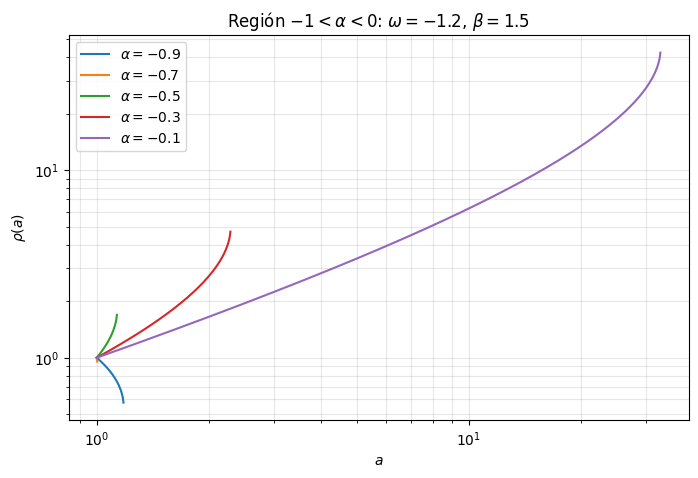

In [12]:
omega_fixed = -1.2
beta_fixed = 1.5
alpha_values_negative = [-0.9, -0.7, -0.5, -0.3, -0.1]

plt.figure(figsize=(8, 5))

for alpha in alpha_values_negative:
    try:
        amax_allowed = lambert_real_domain_amax(
            omega=omega_fixed,
            alpha=alpha,
            beta=beta_fixed,
            rho0=1.0,
            a0=1.0,
        )

        if amax_allowed is None:
            a_values_neg = np.logspace(0, 3, 1000)
        else:
            if amax_allowed <= 1.0:
                print(f"alpha={alpha}: acrit={amax_allowed:.4f}, no hay rango futuro suficiente.")
                continue

            a_values_neg = np.logspace(
                0,
                np.log10(amax_allowed),
                1000,
            )

        params = BarotropicPowerDiffusionParams(
            omega=omega_fixed,
            alpha=alpha,
            beta=beta_fixed,
            rho0=1.0,
            a0=1.0,
        )

        model = BarotropicPowerDiffusionModel(params)

        # Para alpha < 0 suele ser más seguro usar branch="auto" o branch=-1.
        rho_values = model.rho_of_a_lambert(a_values_neg, branch="auto")

        plt.plot(
            a_values_neg,
            rho_values,
            label=rf"$\alpha={alpha}$",
        )

    except Exception as e:
        print(f"No se pudo calcular alpha={alpha}: {e}")

plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"$a$")
plt.ylabel(r"$\rho(a)$")
plt.title(
    rf"Región $-1<\alpha<0$: $\omega={omega_fixed}$, $\beta={beta_fixed}$"
)
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

## 4. Exploración gráfica del barrido

Distribuciones, factores de crecimiento y trayectorias seleccionadas.

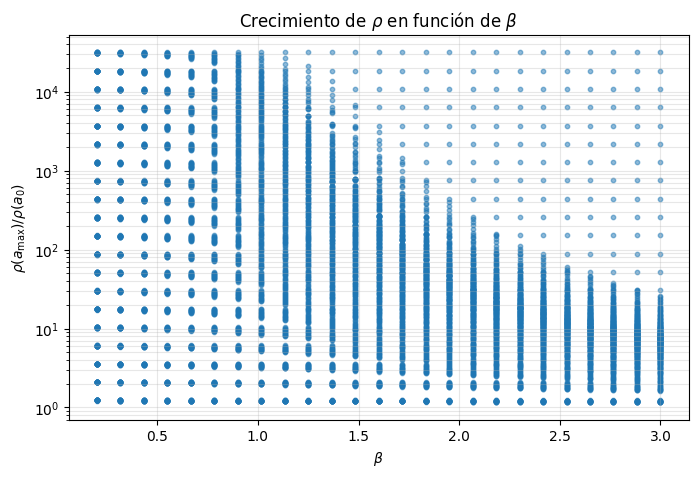

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(
    df_valid["beta"],
    df_valid["rho_growth_factor"],
    s=10,
    alpha=0.5,
)
plt.yscale("log")
plt.xlabel(r"$\beta$")
plt.ylabel(r"$\rho(a_{\max})/\rho(a_0)$")
plt.title(r"Crecimiento de $\rho$ en función de $\beta$")
plt.grid(True, which="both", alpha=0.3)
plt.show()

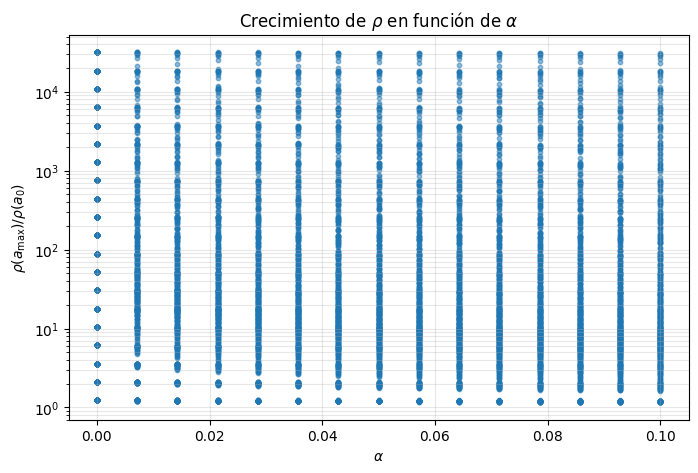

In [14]:
plt.figure(figsize=(8, 5))
plt.scatter(
    df_valid["alpha"],
    df_valid["rho_growth_factor"],
    s=10,
    alpha=0.5,
)
plt.yscale("log")
plt.xlabel(r"$\alpha$")
plt.ylabel(r"$\rho(a_{\max})/\rho(a_0)$")
plt.title(r"Crecimiento de $\rho$ en función de $\alpha$")
plt.grid(True, which="both", alpha=0.3)
plt.show()

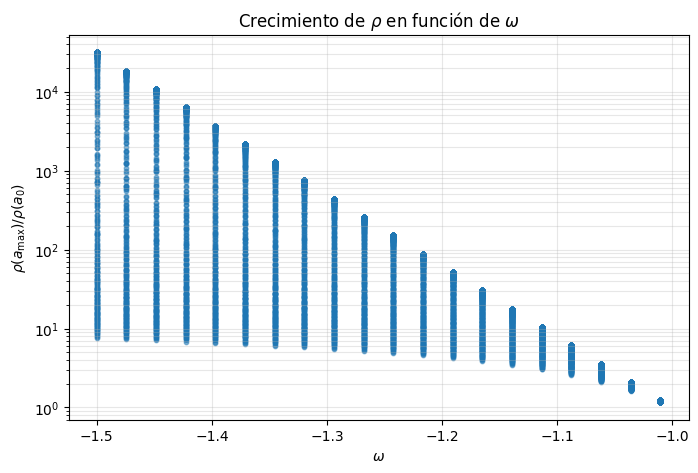

In [15]:
plt.figure(figsize=(8, 5))
plt.scatter(
    df_valid["omega"],
    df_valid["rho_growth_factor"],
    s=10,
    alpha=0.5,
)
plt.yscale("log")
plt.xlabel(r"$\omega$")
plt.ylabel(r"$\rho(a_{\max})/\rho(a_0)$")
plt.title(r"Crecimiento de $\rho$ en función de $\omega$")
plt.grid(True, which="both", alpha=0.3)
plt.show()

In [16]:
df_valid = df_params[df_params["valid_solution"]].copy()

a_values = np.logspace(0, 3, 1000)

In [17]:
df_sorted = df_valid.sort_values("rho_growth_factor").copy()

selected_rows = pd.concat(
    [
        df_sorted.head(3),                                      # crecimiento bajo
        df_sorted.iloc[len(df_sorted)//2 - 1:len(df_sorted)//2 + 2],  # crecimiento medio
        df_sorted.tail(3),                                      # crecimiento alto
    ]
)

selected_rows[
    ["omega", "alpha", "beta", "rho_growth_factor"]
]

,omega,alpha,beta,rho_growth_factor
7499,-1.010000,0.100000,3.000000,1.165768
7498,-1.010000,0.100000,2.883333,1.167939
7474,-1.010000,0.092857,3.000000,1.169023
4388,-1.216316,0.071429,1.716667,21.947749
993,-1.448421,0.064286,2.300000,21.977618
5232,-1.164737,0.100000,1.016667,22.006982
24,-1.500000,0.000000,3.000000,31622.776602
12,-1.500000,0.000000,1.600000,31622.776602
0,-1.500000,0.000000,0.200000,31622.776602


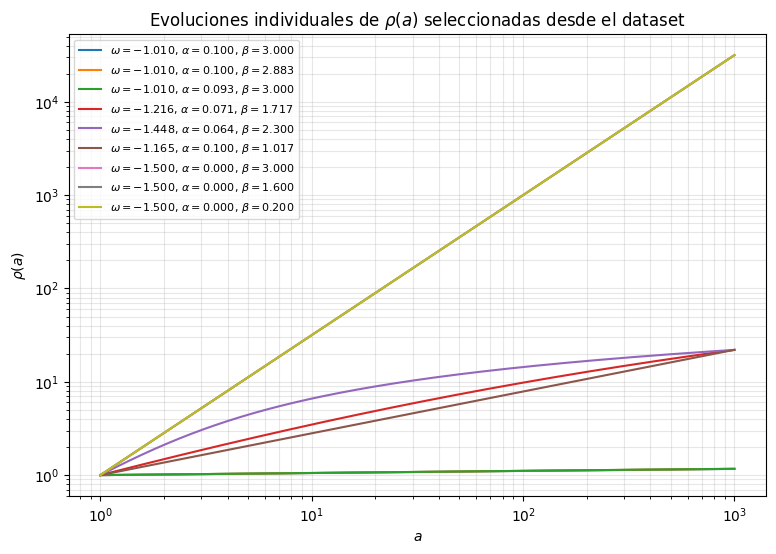

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

for _, row in selected_rows.iterrows():
    omega = row["omega"]
    alpha = row["alpha"]
    beta = row["beta"]

    try:
        params = BarotropicPowerDiffusionParams(
            omega=omega,
            alpha=alpha,
            beta=beta,
            rho0=1.0,
            a0=1.0,
        )

        model = BarotropicPowerDiffusionModel(params)
        rho_values = model.rho_of_a(a_values)

        label = (
            rf"$\omega={omega:.3f}$, "
            rf"$\alpha={alpha:.3f}$, "
            rf"$\beta={beta:.3f}$"
        )

        plt.plot(a_values, rho_values, label=label)

    except Exception as e:
        print(
            f"No se pudo graficar omega={omega}, alpha={alpha}, beta={beta}: {e}"
        )

plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"$a$")
plt.ylabel(r"$\rho(a)$")
plt.title(r"Evoluciones individuales de $\rho(a)$ seleccionadas desde el dataset")
plt.legend(fontsize=8)
plt.grid(True, which="both", alpha=0.3)
plt.show()

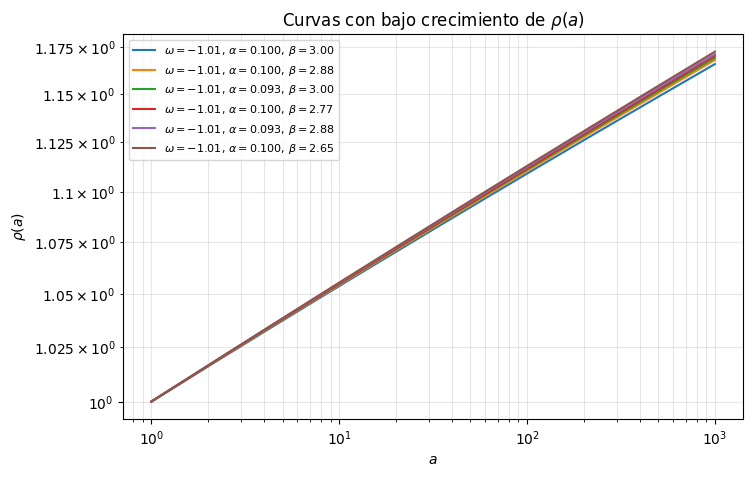

In [19]:
low_growth_rows = df_sorted.head(6)

plt.figure(figsize=(8, 5))

for _, row in low_growth_rows.iterrows():
    params = BarotropicPowerDiffusionParams(
        omega=row["omega"],
        alpha=row["alpha"],
        beta=row["beta"],
        rho0=1.0,
        a0=1.0,
    )

    model = BarotropicPowerDiffusionModel(params)
    rho_values = model.rho_of_a(a_values)

    plt.plot(
        a_values,
        rho_values,
        label=rf"$\omega={row['omega']:.2f}$, $\alpha={row['alpha']:.3f}$, $\beta={row['beta']:.2f}$",
    )

plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"$a$")
plt.ylabel(r"$\rho(a)$")
plt.title(r"Curvas con bajo crecimiento de $\rho(a)$")
plt.legend(fontsize=8)
plt.grid(True, which="both", alpha=0.3)
plt.show()

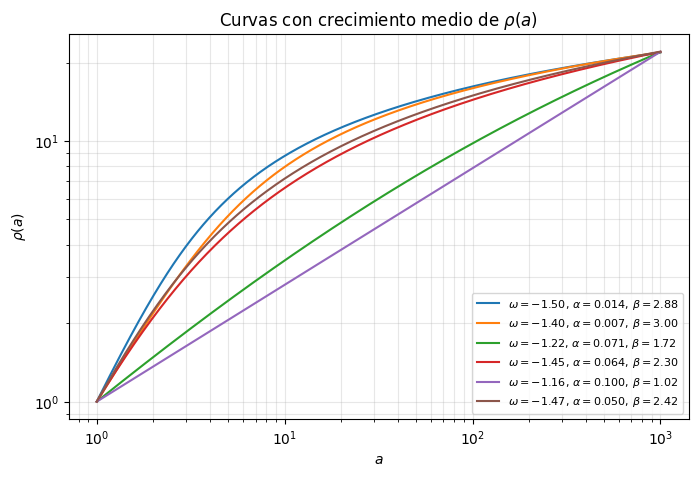

In [20]:
middle_index = len(df_sorted) // 2
medium_growth_rows = df_sorted.iloc[middle_index - 3:middle_index + 3]

plt.figure(figsize=(8, 5))

for _, row in medium_growth_rows.iterrows():
    params = BarotropicPowerDiffusionParams(
        omega=row["omega"],
        alpha=row["alpha"],
        beta=row["beta"],
        rho0=1.0,
        a0=1.0,
    )

    model = BarotropicPowerDiffusionModel(params)
    rho_values = model.rho_of_a(a_values)

    plt.plot(
        a_values,
        rho_values,
        label=rf"$\omega={row['omega']:.2f}$, $\alpha={row['alpha']:.3f}$, $\beta={row['beta']:.2f}$",
    )

plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"$a$")
plt.ylabel(r"$\rho(a)$")
plt.title(r"Curvas con crecimiento medio de $\rho(a)$")
plt.legend(fontsize=8)
plt.grid(True, which="both", alpha=0.3)
plt.show()

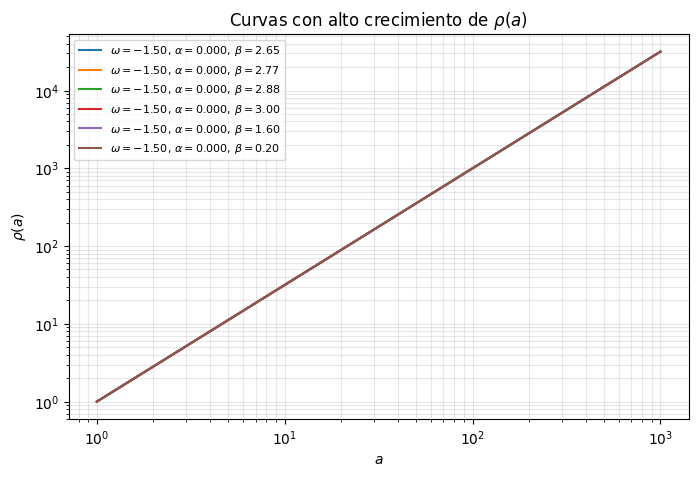

In [21]:
high_growth_rows = df_sorted.tail(6)

plt.figure(figsize=(8, 5))

for _, row in high_growth_rows.iterrows():
    params = BarotropicPowerDiffusionParams(
        omega=row["omega"],
        alpha=row["alpha"],
        beta=row["beta"],
        rho0=1.0,
        a0=1.0,
    )

    model = BarotropicPowerDiffusionModel(params)
    rho_values = model.rho_of_a(a_values)

    plt.plot(
        a_values,
        rho_values,
        label=rf"$\omega={row['omega']:.2f}$, $\alpha={row['alpha']:.3f}$, $\beta={row['beta']:.2f}$",
    )

plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"$a$")
plt.ylabel(r"$\rho(a)$")
plt.title(r"Curvas con alto crecimiento de $\rho(a)$")
plt.legend(fontsize=8)
plt.grid(True, which="both", alpha=0.3)
plt.show()

## 5. Reconstrucción paramétrica de \(\rho(t)\)

Obtención de \(t(a)\) y representación de \(\rho(t)\) a partir de la solución analítica \(\rho(a)\).

# $\rho(t)$

In [22]:
import numpy as np
import matplotlib.pyplot as plt

from src.models import (
    BarotropicPowerDiffusionParams,
    BarotropicPowerDiffusionModel,
)

from src.singularities import SingularityType

params = BarotropicPowerDiffusionParams(
    omega=-1.2,
    alpha=0.05,
    beta=1.5,
    rho0=1.0,
    a0=1.0,
    t0=0.0,
)

model = BarotropicPowerDiffusionModel(params)

a_values = np.logspace(0, 3, 1000)

df_bg = model.evaluate_background(a_values)

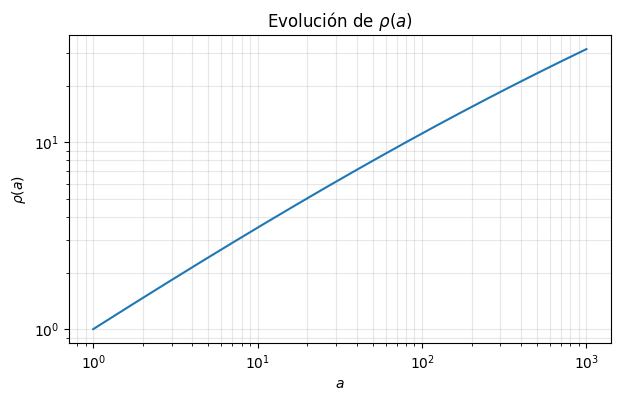

In [23]:
plt.figure(figsize=(7, 4))
plt.plot(df_bg["a"], df_bg["rho"])
plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"$a$")
plt.ylabel(r"$\rho(a)$")
plt.title(r"Evolución de $\rho(a)$")
plt.grid(True, which="both", alpha=0.3)
plt.show()

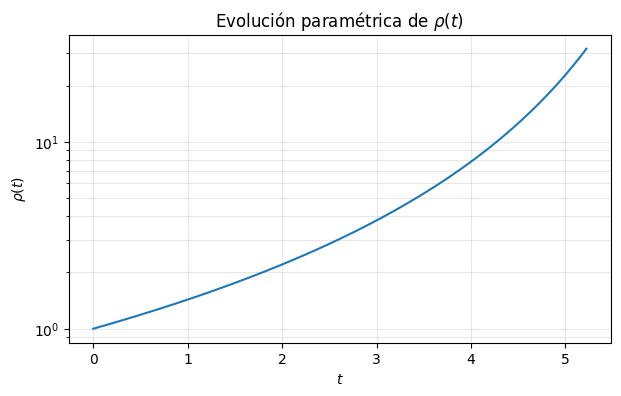

In [24]:
plt.figure(figsize=(7, 4))
plt.plot(df_bg["t"], df_bg["rho"])
plt.yscale("log")
plt.xlabel(r"$t$")
plt.ylabel(r"$\rho(t)$")
plt.title(r"Evolución paramétrica de $\rho(t)$")
plt.grid(True, which="both", alpha=0.3)
plt.show()

In [25]:
"evaluate_background" in dir(model)

True

## 6. Variación independiente de parámetros

Comparación de las curvas al variar \(\alpha\), \(\beta\) y \(\omega\).

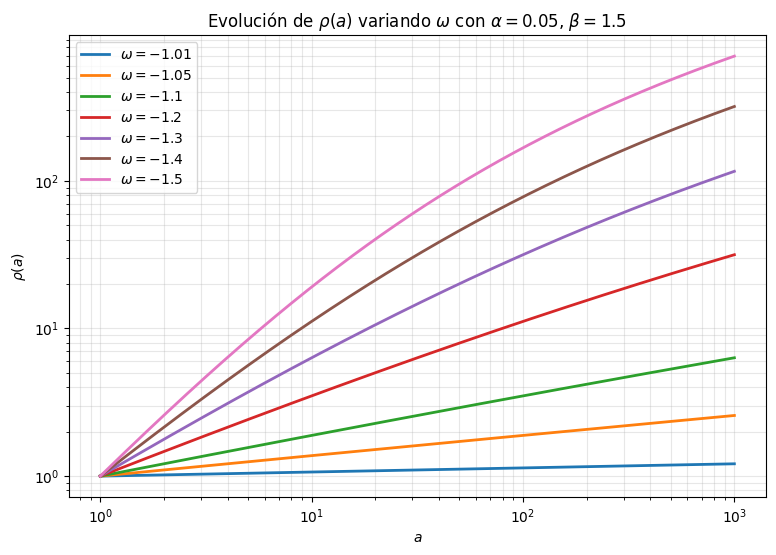

In [26]:
import numpy as np
import matplotlib.pyplot as plt

from src.models import (
    BarotropicPowerDiffusionParams,
    BarotropicPowerDiffusionModel,
)

a_values = np.logspace(0, 3, 1000)

omega_values = [-1.01, -1.05, -1.1, -1.2, -1.3, -1.4, -1.5]

alpha_fixed = 0.05
beta_fixed = 1.5

plt.figure(figsize=(9, 6))

for omega in omega_values:
    params = BarotropicPowerDiffusionParams(
        omega=omega,
        alpha=alpha_fixed,
        beta=beta_fixed,
        rho0=1.0,
        a0=1.0,
        t0=0.0,
    )

    model = BarotropicPowerDiffusionModel(params)
    rho_values = model.rho_of_a(a_values)

    plt.plot(
        a_values,
        rho_values,
        linewidth=2,
        label=rf"$\omega={omega}$",
    )

plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"$a$")
plt.ylabel(r"$\rho(a)$")
plt.title(
    rf"Evolución de $\rho(a)$ variando $\omega$ "
    rf"con $\alpha={alpha_fixed}$, $\beta={beta_fixed}$"
)
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

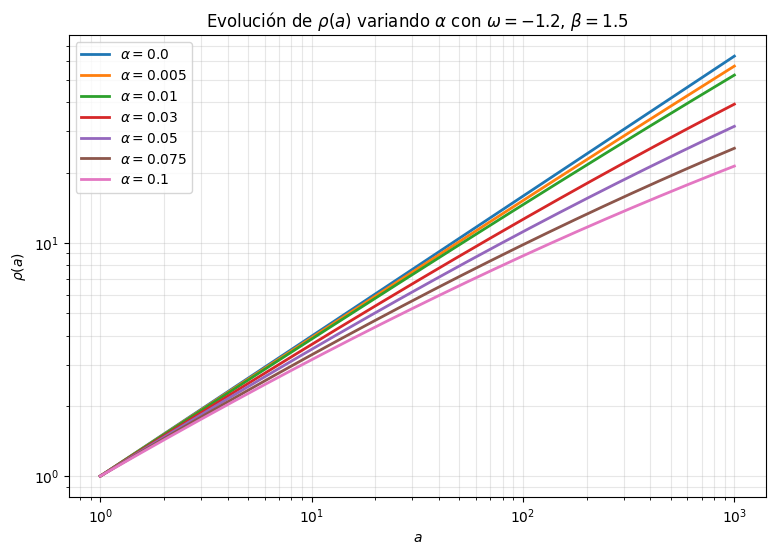

In [27]:
alpha_values = [0.0, 0.005, 0.01, 0.03, 0.05, 0.075, 0.1]

omega_fixed = -1.2
beta_fixed = 1.5

plt.figure(figsize=(9, 6))

for alpha in alpha_values:
    params = BarotropicPowerDiffusionParams(
        omega=omega_fixed,
        alpha=alpha,
        beta=beta_fixed,
        rho0=1.0,
        a0=1.0,
        t0=0.0,
    )

    model = BarotropicPowerDiffusionModel(params)
    rho_values = model.rho_of_a(a_values)

    plt.plot(
        a_values,
        rho_values,
        linewidth=2,
        label=rf"$\alpha={alpha}$",
    )

plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"$a$")
plt.ylabel(r"$\rho(a)$")
plt.title(
    rf"Evolución de $\rho(a)$ variando $\alpha$ "
    rf"con $\omega={omega_fixed}$, $\beta={beta_fixed}$"
)
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

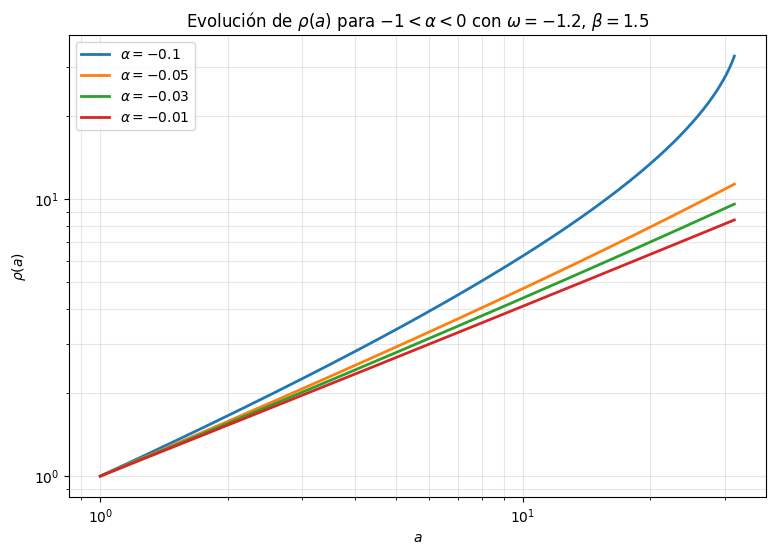

In [28]:
alpha_values_negative = [-0.1, -0.05, -0.03, -0.01]

omega_fixed = -1.2
beta_fixed = 1.5

plt.figure(figsize=(9, 6))

for alpha in alpha_values_negative:
    try:
        params = BarotropicPowerDiffusionParams(
            omega=omega_fixed,
            alpha=alpha,
            beta=beta_fixed,
            rho0=1.0,
            a0=1.0,
            t0=0.0,
        )

        model = BarotropicPowerDiffusionModel(params)

        # Para alpha negativo conviene acortar el rango de a.
        a_values_neg = np.logspace(0, 1.5, 700)  # de 1 a ~31.6

        rho_values = model.rho_of_a_lambert(a_values_neg, branch="auto")

        plt.plot(
            a_values_neg,
            rho_values,
            linewidth=2,
            label=rf"$\alpha={alpha}$",
        )

    except Exception as e:
        print(f"No se pudo calcular alpha={alpha}: {e}")

plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"$a$")
plt.ylabel(r"$\rho(a)$")
plt.title(
    rf"Evolución de $\rho(a)$ para $-1<\alpha<0$ "
    rf"con $\omega={omega_fixed}$, $\beta={beta_fixed}$"
)
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

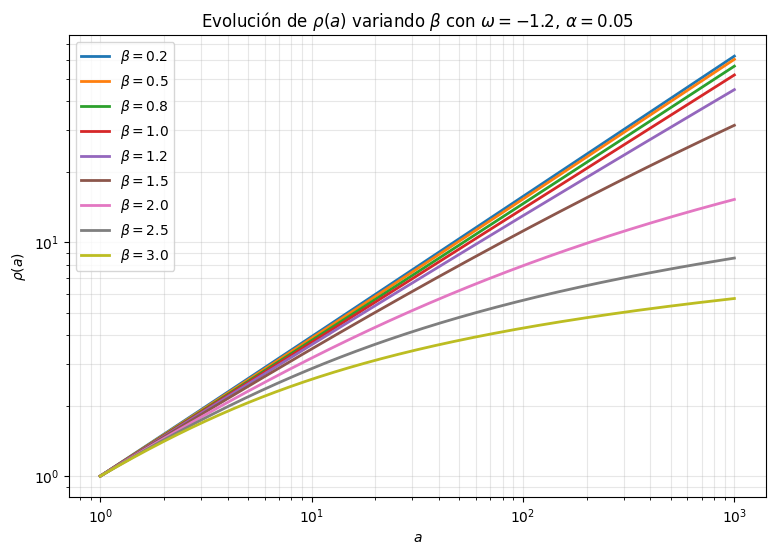

In [29]:
beta_values = [0.2, 0.5, 0.8, 1.0, 1.2, 1.5, 2.0, 2.5, 3.0]

omega_fixed = -1.2
alpha_fixed = 0.05

plt.figure(figsize=(9, 6))

for beta in beta_values:
    params = BarotropicPowerDiffusionParams(
        omega=omega_fixed,
        alpha=alpha_fixed,
        beta=beta,
        rho0=1.0,
        a0=1.0,
        t0=0.0,
    )

    model = BarotropicPowerDiffusionModel(params)
    rho_values = model.rho_of_a(a_values)

    plt.plot(
        a_values,
        rho_values,
        linewidth=2,
        label=rf"$\beta={beta}$",
    )

plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"$a$")
plt.ylabel(r"$\rho(a)$")
plt.title(
    rf"Evolución de $\rho(a)$ variando $\beta$ "
    rf"con $\omega={omega_fixed}$, $\alpha={alpha_fixed}$"
)
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

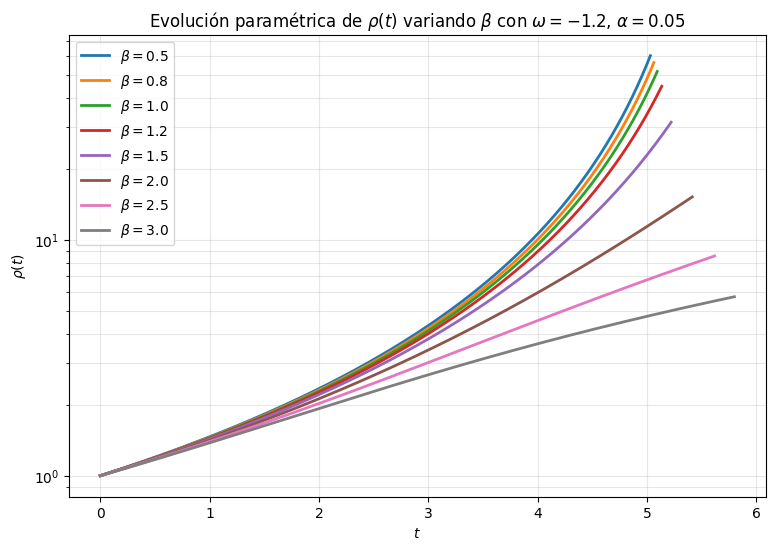

In [30]:
beta_values = [0.5, 0.8, 1.0, 1.2, 1.5, 2.0, 2.5, 3.0]

omega_fixed = -1.2
alpha_fixed = 0.05

a_values = np.logspace(0, 3, 1000)

plt.figure(figsize=(9, 6))

for beta in beta_values:
    try:
        params = BarotropicPowerDiffusionParams(
            omega=omega_fixed,
            alpha=alpha_fixed,
            beta=beta,
            rho0=1.0,
            a0=1.0,
            t0=0.0,
        )

        model = BarotropicPowerDiffusionModel(params)
        df_bg = model.evaluate_background(a_values)

        plt.plot(
            df_bg["t"],
            df_bg["rho"],
            linewidth=2,
            label=rf"$\beta={beta}$",
        )

    except Exception as e:
        print(f"No se pudo calcular beta={beta}: {e}")

plt.yscale("log")
plt.xlabel(r"$t$")
plt.ylabel(r"$\rho(t)$")
plt.title(
    rf"Evolución paramétrica de $\rho(t)$ variando $\beta$ "
    rf"con $\omega={omega_fixed}$, $\alpha={alpha_fixed}$"
)
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

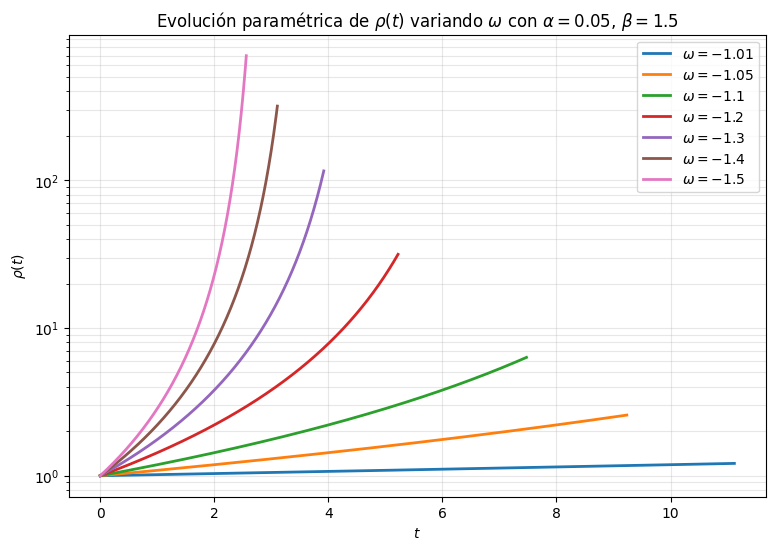

In [33]:
omega_values = [-1.01, -1.05, -1.1, -1.2, -1.3, -1.4, -1.5]

alpha_fixed = 0.05
beta_fixed = 1.5

a_values = np.logspace(0, 3, 1000)

plt.figure(figsize=(9, 6))

for omega in omega_values:
    try:
        params = BarotropicPowerDiffusionParams(
            omega=omega,
            alpha=alpha_fixed,
            beta=beta_fixed,
            rho0=1.0,
            a0=1.0,
            t0=0.0,
        )

        model = BarotropicPowerDiffusionModel(params)
        df_bg = model.evaluate_background(a_values)

        plt.plot(
            df_bg["t"],
            df_bg["rho"],
            linewidth=2,
            label=rf"$\omega={omega}$",
        )

    except Exception as e:
        print(f"No se pudo calcular omega={omega}: {e}")

plt.yscale("log")
plt.xlabel(r"$t$")
plt.ylabel(r"$\rho(t)$")
plt.title(
    rf"Evolución paramétrica de $\rho(t)$ variando $\omega$ "
    rf"con $\alpha={alpha_fixed}$, $\beta={beta_fixed}$"
)
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

No se pudo calcular alpha=-0.05: Lambert W devolvió valores complejos no despreciables. Revisa la rama elegida o el rango de a.
No se pudo calcular alpha=-0.075: Lambert W devolvió valores complejos no despreciables. Revisa la rama elegida o el rango de a.
No se pudo calcular alpha=-0.1: Lambert W devolvió valores complejos no despreciables. Revisa la rama elegida o el rango de a.


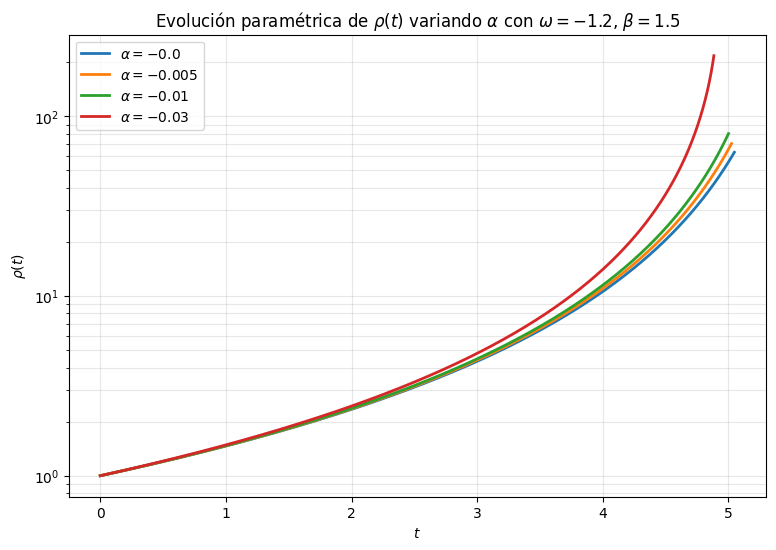

In [38]:
alpha_values = [-0.0, -0.005, -0.01, -0.03, -0.05, -0.075, -0.1]

omega_fixed = -1.2
beta_fixed = 1.5

a_values = np.logspace(0, 3, 1000)

plt.figure(figsize=(9, 6))

for alpha in alpha_values:
    try:
        params = BarotropicPowerDiffusionParams(
            omega=omega_fixed,
            alpha=alpha,
            beta=beta_fixed,
            rho0=1.0,
            a0=1.0,
            t0=0.0,
        )

        model = BarotropicPowerDiffusionModel(params)
        df_bg = model.evaluate_background(a_values)

        plt.plot(
            df_bg["t"],
            df_bg["rho"],
            linewidth=2,
            label=rf"$\alpha={alpha}$",
        )

    except Exception as e:
        print(f"No se pudo calcular alpha={alpha}: {e}")

plt.yscale("log")
plt.xlabel(r"$t$")
plt.ylabel(r"$\rho(t)$")
plt.title(
    rf"Evolución paramétrica de $\rho(t)$ variando $\alpha$ "
    rf"con $\omega={omega_fixed}$, $\beta={beta_fixed}$"
)
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

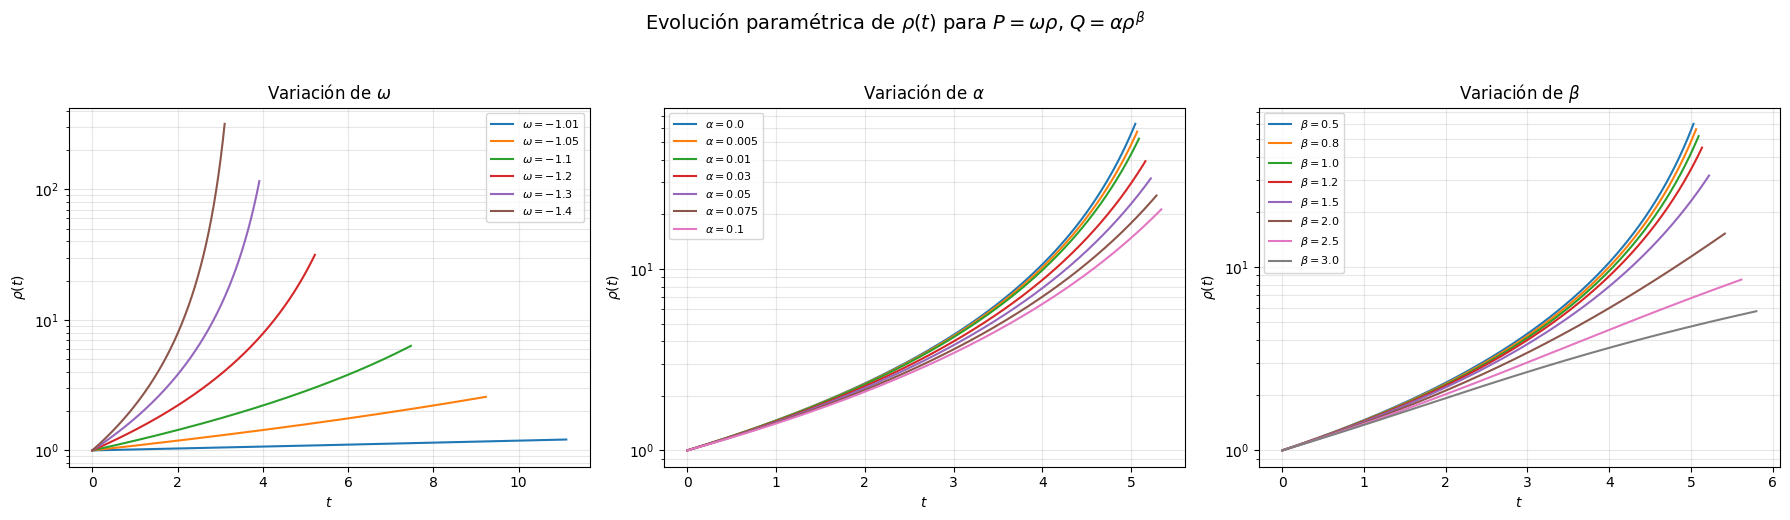

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

a_values = np.logspace(0, 3, 1000)

# Panel 1: variar omega
omega_values = [-1.01, -1.05, -1.1, -1.2, -1.3, -1.4]
alpha_fixed = 0.05
beta_fixed = 1.5

for omega in omega_values:
    params = BarotropicPowerDiffusionParams(
        omega=omega,
        alpha=alpha_fixed,
        beta=beta_fixed,
        rho0=1.0,
        a0=1.0,
        t0=0.0,
    )
    model = BarotropicPowerDiffusionModel(params)
    df_bg = model.evaluate_background(a_values)

    axes[0].plot(df_bg["t"], df_bg["rho"], label=rf"$\omega={omega}$")

axes[0].set_yscale("log")
axes[0].set_xlabel(r"$t$")
axes[0].set_ylabel(r"$\rho(t)$")
axes[0].set_title(r"Variación de $\omega$")
axes[0].grid(True, which="both", alpha=0.3)
axes[0].legend(fontsize=8)

# Panel 2: variar alpha
alpha_values = [0.0, 0.005, 0.01, 0.03, 0.05, 0.075, 0.1]
omega_fixed = -1.2
beta_fixed = 1.5

for alpha in alpha_values:
    params = BarotropicPowerDiffusionParams(
        omega=omega_fixed,
        alpha=alpha,
        beta=beta_fixed,
        rho0=1.0,
        a0=1.0,
        t0=0.0,
    )
    model = BarotropicPowerDiffusionModel(params)
    df_bg = model.evaluate_background(a_values)

    axes[1].plot(df_bg["t"], df_bg["rho"], label=rf"$\alpha={alpha}$")

axes[1].set_yscale("log")
axes[1].set_xlabel(r"$t$")
axes[1].set_ylabel(r"$\rho(t)$")
axes[1].set_title(r"Variación de $\alpha$")
axes[1].grid(True, which="both", alpha=0.3)
axes[1].legend(fontsize=8)

# Panel 3: variar beta
beta_values = [0.5, 0.8, 1.0, 1.2, 1.5, 2.0, 2.5, 3.0]
omega_fixed = -1.2
alpha_fixed = 0.05

for beta in beta_values:
    params = BarotropicPowerDiffusionParams(
        omega=omega_fixed,
        alpha=alpha_fixed,
        beta=beta,
        rho0=1.0,
        a0=1.0,
        t0=0.0,
    )
    model = BarotropicPowerDiffusionModel(params)
    df_bg = model.evaluate_background(a_values)

    axes[2].plot(df_bg["t"], df_bg["rho"], label=rf"$\beta={beta}$")

axes[2].set_yscale("log")
axes[2].set_xlabel(r"$t$")
axes[2].set_ylabel(r"$\rho(t)$")
axes[2].set_title(r"Variación de $\beta$")
axes[2].grid(True, which="both", alpha=0.3)
axes[2].legend(fontsize=8)

fig.suptitle(
    r"Evolución paramétrica de $\rho(t)$ para "
    r"$P=\omega\rho$, $Q=\alpha\rho^\beta$",
    y=1.03,
    fontsize=14,
)

plt.tight_layout()
plt.show()

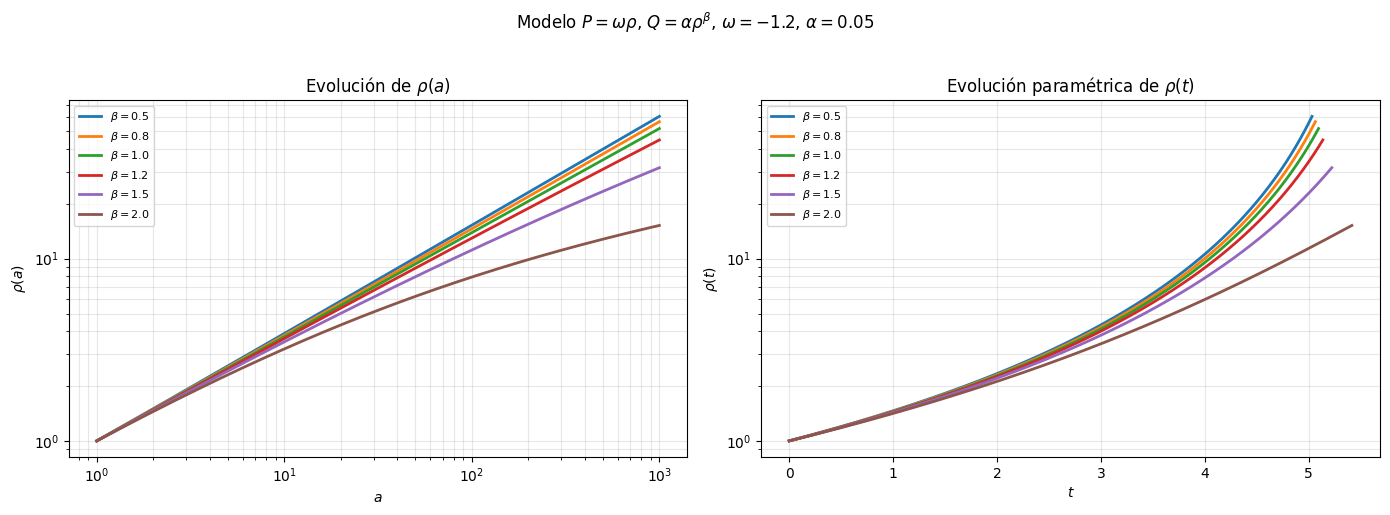

In [31]:
beta_values = [0.5, 0.8, 1.0, 1.2, 1.5, 2.0]

omega_fixed = -1.2
alpha_fixed = 0.05

a_values = np.logspace(0, 3, 1000)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for beta in beta_values:
    params = BarotropicPowerDiffusionParams(
        omega=omega_fixed,
        alpha=alpha_fixed,
        beta=beta,
        rho0=1.0,
        a0=1.0,
        t0=0.0,
    )

    model = BarotropicPowerDiffusionModel(params)
    df_bg = model.evaluate_background(a_values)

    axes[0].plot(
        df_bg["a"],
        df_bg["rho"],
        linewidth=2,
        label=rf"$\beta={beta}$",
    )

    axes[1].plot(
        df_bg["t"],
        df_bg["rho"],
        linewidth=2,
        label=rf"$\beta={beta}$",
    )

axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel(r"$a$")
axes[0].set_ylabel(r"$\rho(a)$")
axes[0].set_title(r"Evolución de $\rho(a)$")
axes[0].grid(True, which="both", alpha=0.3)

axes[1].set_yscale("log")
axes[1].set_xlabel(r"$t$")
axes[1].set_ylabel(r"$\rho(t)$")
axes[1].set_title(r"Evolución paramétrica de $\rho(t)$")
axes[1].grid(True, which="both", alpha=0.3)

axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)

fig.suptitle(
    rf"Modelo $P=\omega\rho$, $Q=\alpha\rho^\beta$, "
    rf"$\omega={omega_fixed}$, $\alpha={alpha_fixed}$",
    y=1.02,
)

plt.tight_layout()
plt.show()

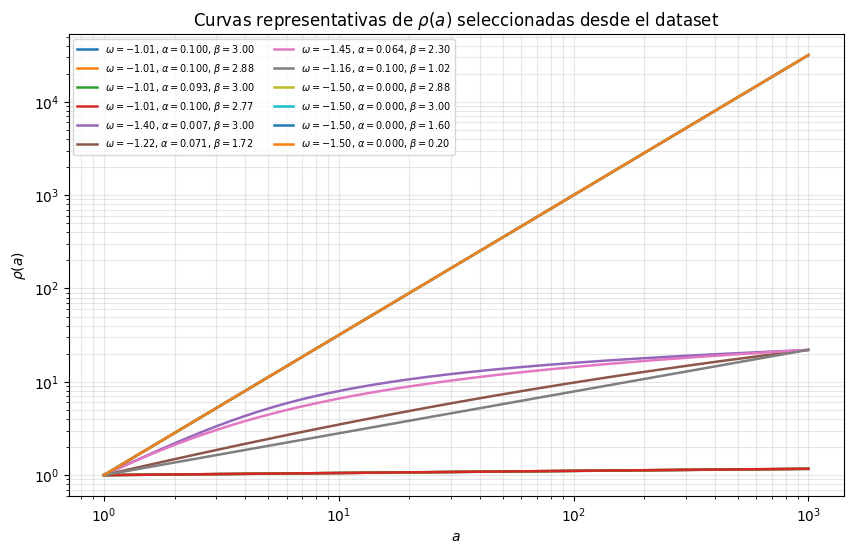

In [32]:
df_sorted = df_valid.sort_values("rho_growth_factor").copy()

selected_rows = pd.concat(
    [
        df_sorted.head(4),
        df_sorted.iloc[len(df_sorted)//2 - 2:len(df_sorted)//2 + 2],
        df_sorted.tail(4),
    ]
)

plt.figure(figsize=(10, 6))

for _, row in selected_rows.iterrows():
    try:
        params = BarotropicPowerDiffusionParams(
            omega=row["omega"],
            alpha=row["alpha"],
            beta=row["beta"],
            rho0=1.0,
            a0=1.0,
            t0=0.0,
        )

        model = BarotropicPowerDiffusionModel(params)
        rho_values = model.rho_of_a(a_values)

        label = (
            rf"$\omega={row['omega']:.2f}$, "
            rf"$\alpha={row['alpha']:.3f}$, "
            rf"$\beta={row['beta']:.2f}$"
        )

        plt.plot(a_values, rho_values, linewidth=1.8, label=label)

    except Exception as e:
        print(f"No se pudo graficar una fila: {e}")

plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"$a$")
plt.ylabel(r"$\rho(a)$")
plt.title(r"Curvas representativas de $\rho(a)$ seleccionadas desde el dataset")
plt.legend(fontsize=7, ncol=2)
plt.grid(True, which="both", alpha=0.3)
plt.show()

## 7. Comparación con una ODE directa

Verificación del método paramétrico mediante una integración independiente de la ecuación para la densidad.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import lambertw

params = BarotropicPowerDiffusionParams(
    omega=-1.2,
    alpha=0.05,
    beta=1.5,
    rho0=1.0,
    a0=1.0,
    t0=0.0,
)

model = BarotropicPowerDiffusionModel(params)

# Método paramétrico
a_values = np.logspace(0, 3, 1000)
df_bg = model.evaluate_background(a_values)

t_param = df_bg["t"].to_numpy()
rho_param = df_bg["rho"].to_numpy()

# Método ODE directa
def drho_dt(t, y):
    rho = y[0]

    omega = params.omega
    alpha = params.alpha
    beta = params.beta

    factor_H = 1.0 + alpha * rho ** (beta - 1.0)
    denominator = 1.0 + alpha * beta * rho ** (beta - 1.0)

    if rho <= 0 or factor_H <= 0 or denominator == 0:
        return [np.nan]

    return [
        -np.sqrt(3.0)
        * (1.0 + omega)
        * rho ** 1.5
        * np.sqrt(factor_H)
        / denominator
    ]

t_span = (t_param[0], t_param[-1])
t_eval = t_param

sol = solve_ivp(
    drho_dt,
    t_span=t_span,
    y0=[params.rho0],
    t_eval=t_eval,
    rtol=1e-9,
    atol=1e-11,
)

rho_ode = sol.y[0]

plt.figure(figsize=(8, 5))

plt.plot(t_param, rho_param, label="Paramétrica: Lambert W + t(a)", linewidth=2)
plt.plot(t_eval, rho_ode, "--", label="ODE directa", linewidth=2)

plt.yscale("log")
plt.xlabel(r"$t$")
plt.ylabel(r"$\rho(t)$")
plt.title(r"Comparación entre solución paramétrica y ODE directa")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

NameError: name 'solve_ivp' is not defined

In [37]:
relative_error = np.abs(rho_param - rho_ode) / np.maximum(np.abs(rho_param), 1e-15)

print("Error relativo máximo:", np.max(relative_error))
print("Error relativo medio:", np.mean(relative_error))

Error relativo máximo: 9.333797968329149e-05
Error relativo medio: 3.819447199676126e-05


## 8. Caso \(\omega=0\)

Estudio gráfico preliminar de los sectores \(\alpha\beta>0\) y \(\alpha\beta<0\).

# $\omega=0$

In [4]:
alpha_beta_positive_cases = [
    {"alpha": 0.01, "beta": 0.5},
    {"alpha": 0.03, "beta": 0.8},
    {"alpha": 0.05, "beta": 1.2},
    {"alpha": 0.10, "beta": 1.5},
    {"alpha": -0.01, "beta": -0.5},
    {"alpha": -0.03, "beta": -1.0},
]

In [5]:
def compute_n(beta, omega=0.0):
    """
    n = -3(beta - 1)(1 + omega).
    """
    return -3.0 * (beta - 1.0) * (1.0 + omega)


def compute_R(beta, omega=0.0, a_min=1.0, a_max=1e3):
    """
    R = max_{a in [a_min, a_max]} a^n.

    Como a^n es monótona para a > 0:
        si n >= 0, R = a_max^n
        si n < 0, R = a_min^n
    """

    n = compute_n(beta, omega)

    if n >= 0:
        return a_max**n

    return a_min**n


def critical_u_values(R):
    """
    Calcula u_- y u_+ desde

        u_- = -W_0(-1/(eR))
        u_+ = -W_{-1}(-1/(eR)).

    Para R = 1, ambos coinciden en u = 1.
    """

    argument = -1.0 / (np.e * R)

    u_minus = -lambertw(argument, k=0).real
    u_plus = -lambertw(argument, k=-1).real

    return u_minus, u_plus


def is_admissible_alpha_beta(
    alpha,
    beta,
    omega=0.0,
    a_min=1.0,
    a_max=1e3,
    tol=1e-12,
):
    """
    Determina si el par (alpha, beta) es admisible según el análisis del texto.

    Caso 1:
        alpha*beta > 0
        admisible directamente usando W0.

    Caso 2:
        alpha*beta < 0
        definimos u = -alpha*beta > 0.
        Se requiere:
            0 < u <= u_-  o  u >= u_+.

    Caso alpha*beta = 0:
        se trata como caso especial.
    """

    s = alpha * beta

    if abs(s) < tol:
        return True

    if s > 0:
        return True

    # Caso s < 0
    u = -s

    R = compute_R(beta=beta, omega=omega, a_min=a_min, a_max=a_max)

    u_minus, u_plus = critical_u_values(R)

    return (0.0 < u <= u_minus) or (u >= u_plus)

In [6]:
omega_fixed = 0.0

a_min = 1.0
a_max = 1e3

a_values = np.logspace(np.log10(a_min), np.log10(a_max), 1200)

In [7]:
cases_alpha_beta_positive = [
    {"alpha": 0.01, "beta": 0.5},
    {"alpha": 0.03, "beta": 0.8},
    {"alpha": 0.05, "beta": 1.2},
    {"alpha": 0.10, "beta": 1.5},
    {"alpha": -0.01, "beta": -0.5},
    {"alpha": -0.03, "beta": -1.0},
]

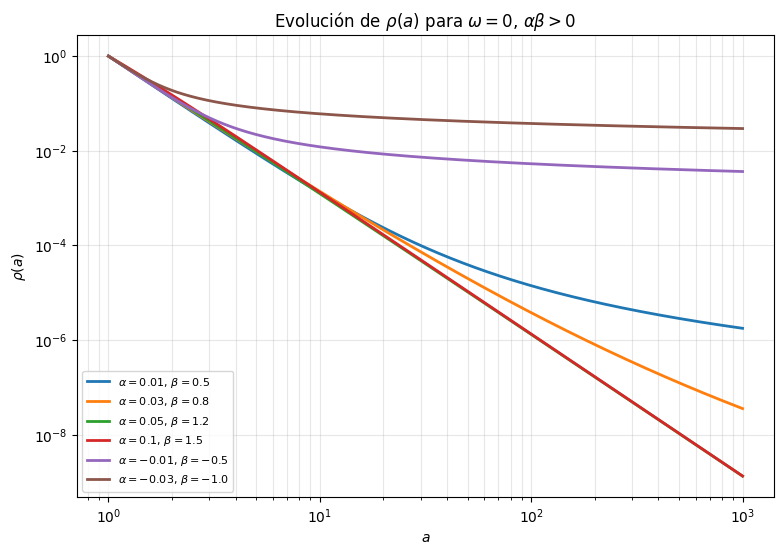

In [8]:
plt.figure(figsize=(9, 6))

for case in cases_alpha_beta_positive:
    alpha = case["alpha"]
    beta = case["beta"]

    if not is_admissible_alpha_beta(
        alpha=alpha,
        beta=beta,
        omega=omega_fixed,
        a_min=a_min,
        a_max=a_max,
    ):
        print(f"No admisible: alpha={alpha}, beta={beta}")
        continue

    try:
        params = BarotropicPowerDiffusionParams(
            omega=omega_fixed,
            alpha=alpha,
            beta=beta,
            rho0=1.0,
            a0=1.0,
            t0=0.0,
        )

        model = BarotropicPowerDiffusionModel(params)
        rho_values = model.rho_of_a(a_values)

        plt.plot(
            a_values,
            rho_values,
            linewidth=2,
            label=rf"$\alpha={alpha}$, $\beta={beta}$",
        )

    except Exception as e:
        print(f"No se pudo graficar alpha={alpha}, beta={beta}: {e}")

plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"$a$")
plt.ylabel(r"$\rho(a)$")
plt.title(r"Evolución de $\rho(a)$ para $\omega=0$, $\alpha\beta>0$")
plt.legend(fontsize=8)
plt.grid(True, which="both", alpha=0.3)
plt.show()

No se pudo graficar alpha=-0.01, beta=-0.5: rho_eff = rho + Q debe ser positiva para calcular H(a).
No se pudo graficar alpha=-0.03, beta=-1.0: rho_eff = rho + Q debe ser positiva para calcular H(a).


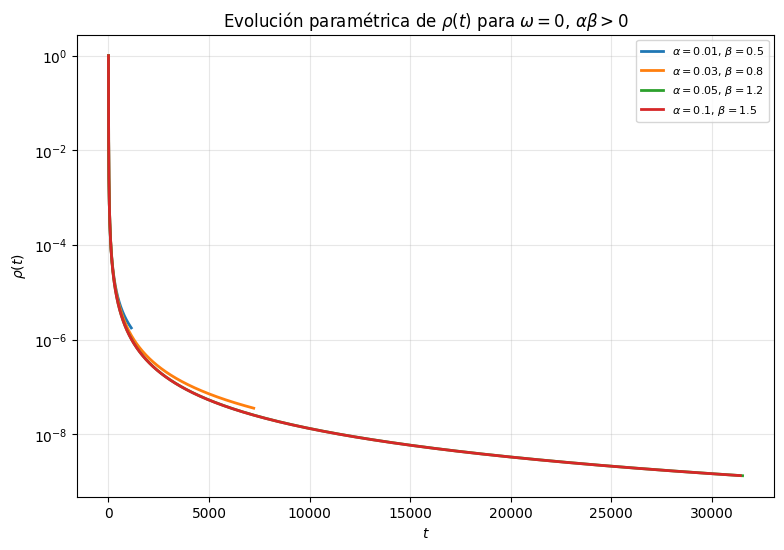

In [9]:
plt.figure(figsize=(9, 6))

for case in cases_alpha_beta_positive:
    alpha = case["alpha"]
    beta = case["beta"]

    if not is_admissible_alpha_beta(
        alpha=alpha,
        beta=beta,
        omega=omega_fixed,
        a_min=a_min,
        a_max=a_max,
    ):
        continue

    try:
        params = BarotropicPowerDiffusionParams(
            omega=omega_fixed,
            alpha=alpha,
            beta=beta,
            rho0=1.0,
            a0=1.0,
            t0=0.0,
        )

        model = BarotropicPowerDiffusionModel(params)
        df_bg = model.evaluate_background(a_values)

        plt.plot(
            df_bg["t"],
            df_bg["rho"],
            linewidth=2,
            label=rf"$\alpha={alpha}$, $\beta={beta}$",
        )

    except Exception as e:
        print(f"No se pudo graficar alpha={alpha}, beta={beta}: {e}")

plt.yscale("log")
plt.xlabel(r"$t$")
plt.ylabel(r"$\rho(t)$")
plt.title(r"Evolución paramétrica de $\rho(t)$ para $\omega=0$, $\alpha\beta>0$")
plt.legend(fontsize=8)
plt.grid(True, which="both", alpha=0.3)
plt.show()

In [10]:
candidate_cases_alpha_beta_negative = []

alpha_candidates = np.concatenate([
    -np.logspace(-3, -0.05, 40),  # negativos
    np.logspace(-3, -0.05, 40),   # positivos
])

beta_candidates = np.concatenate([
    -np.linspace(0.2, 3.0, 30),
    np.linspace(0.2, 3.0, 30),
])

for alpha in alpha_candidates:
    for beta in beta_candidates:
        if alpha * beta >= 0:
            continue

        if abs(beta - 1.0) < 1e-8:
            continue

        if is_admissible_alpha_beta(
            alpha=alpha,
            beta=beta,
            omega=omega_fixed,
            a_min=a_min,
            a_max=a_max,
        ):
            candidate_cases_alpha_beta_negative.append(
                {
                    "alpha": float(alpha),
                    "beta": float(beta),
                    "u": float(-alpha * beta),
                    "R": float(compute_R(beta, omega_fixed, a_min, a_max)),
                }
            )

df_ab_negative = pd.DataFrame(candidate_cases_alpha_beta_negative)

df_ab_negative.head(), len(df_ab_negative)

(     alpha      beta         u          R
 0 -0.00100  0.779310  0.000779  96.873925
 1 -0.00100  0.875862  0.000876  13.099098
 2 -0.00100  0.972414  0.000972   1.771234
 3 -0.00119  0.779310  0.000928  96.873925
 4 -0.00119  0.875862  0.001043  13.099098,
 64)

In [11]:
df_ab_negative_sorted = df_ab_negative.sort_values("u").copy()

selected_negative_cases = pd.concat(
    [
        df_ab_negative_sorted.head(3),
        df_ab_negative_sorted.iloc[
            len(df_ab_negative_sorted)//2 - 2:
            len(df_ab_negative_sorted)//2 + 2
        ],
        df_ab_negative_sorted.tail(3),
    ]
)

selected_negative_cases

,alpha,beta,u,R
0,-0.001000,0.779310,0.000779,96.873925
1,-0.001000,0.875862,0.000876,13.099098
3,-0.001190,0.779310,0.000928,96.873925
30,-0.005707,0.875862,0.004999,13.099098
31,-0.005707,0.972414,0.005550,1.771234
32,-0.006793,0.875862,0.005950,13.099098
33,-0.006793,0.972414,0.006605,1.771234
61,-0.185879,0.972414,0.180751,1.771234
62,-0.221244,0.972414,0.215141,1.771234
63,-0.263338,0.972414,0.256073,1.771234


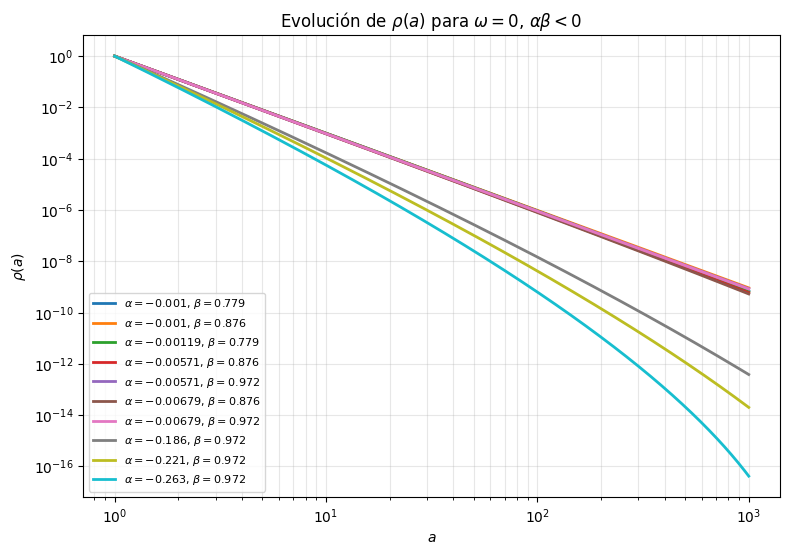

In [12]:
plt.figure(figsize=(9, 6))

for _, row in selected_negative_cases.iterrows():
    alpha = row["alpha"]
    beta = row["beta"]

    try:
        params = BarotropicPowerDiffusionParams(
            omega=omega_fixed,
            alpha=alpha,
            beta=beta,
            rho0=1.0,
            a0=1.0,
            t0=0.0,
        )

        model = BarotropicPowerDiffusionModel(params)
        rho_values = model.rho_of_a_lambert(a_values, branch=0)

        plt.plot(
            a_values,
            rho_values,
            linewidth=2,
            label=rf"$\alpha={alpha:.3g}$, $\beta={beta:.3g}$",
        )

    except Exception as e:
        print(f"No se pudo graficar alpha={alpha}, beta={beta}: {e}")

plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"$a$")
plt.ylabel(r"$\rho(a)$")
plt.title(r"Evolución de $\rho(a)$ para $\omega=0$, $\alpha\beta<0$")
plt.legend(fontsize=8)
plt.grid(True, which="both", alpha=0.3)
plt.show()

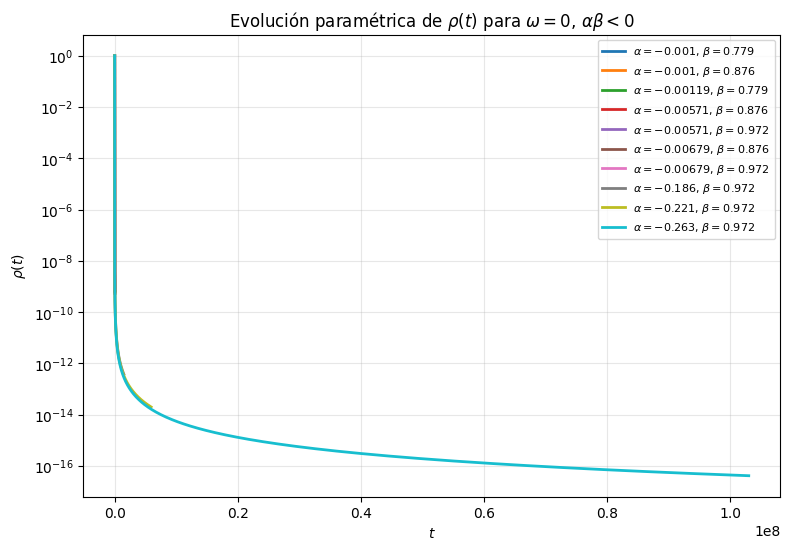

In [13]:
plt.figure(figsize=(9, 6))

for _, row in selected_negative_cases.iterrows():
    alpha = row["alpha"]
    beta = row["beta"]

    try:
        params = BarotropicPowerDiffusionParams(
            omega=omega_fixed,
            alpha=alpha,
            beta=beta,
            rho0=1.0,
            a0=1.0,
            t0=0.0,
        )

        model = BarotropicPowerDiffusionModel(params)
        df_bg = model.evaluate_background(a_values)

        plt.plot(
            df_bg["t"],
            df_bg["rho"],
            linewidth=2,
            label=rf"$\alpha={alpha:.3g}$, $\beta={beta:.3g}$",
        )

    except Exception as e:
        print(f"No se pudo graficar alpha={alpha}, beta={beta}: {e}")

plt.yscale("log")
plt.xlabel(r"$t$")
plt.ylabel(r"$\rho(t)$")
plt.title(r"Evolución paramétrica de $\rho(t)$ para $\omega=0$, $\alpha\beta<0$")
plt.legend(fontsize=8)
plt.grid(True, which="both", alpha=0.3)
plt.show()

Error en alpha beta > 0: rho_eff = rho + Q debe ser positiva para calcular H(a).
Error en alpha beta > 0: rho_eff = rho + Q debe ser positiva para calcular H(a).


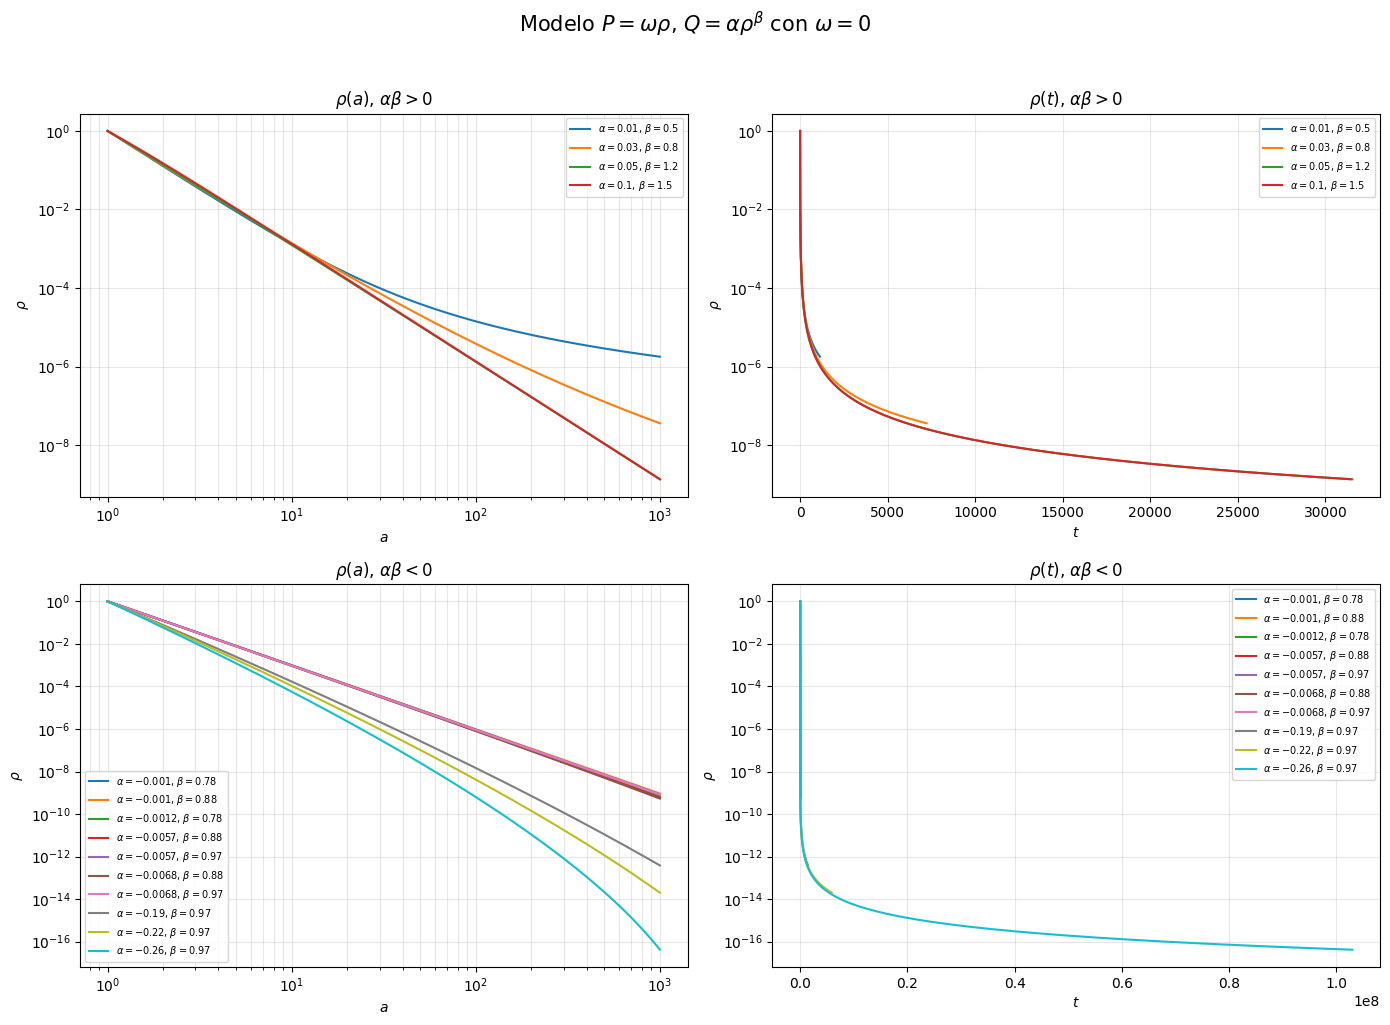

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# alpha beta > 0: rho(a)
for case in cases_alpha_beta_positive:
    alpha = case["alpha"]
    beta = case["beta"]

    try:
        params = BarotropicPowerDiffusionParams(
            omega=omega_fixed,
            alpha=alpha,
            beta=beta,
            rho0=1.0,
            a0=1.0,
            t0=0.0,
        )

        model = BarotropicPowerDiffusionModel(params)
        df_bg = model.evaluate_background(a_values)

        axes[0, 0].plot(df_bg["a"], df_bg["rho"], label=rf"$\alpha={alpha}$, $\beta={beta}$")
        axes[0, 1].plot(df_bg["t"], df_bg["rho"], label=rf"$\alpha={alpha}$, $\beta={beta}$")

    except Exception as e:
        print(f"Error en alpha beta > 0: {e}")

# alpha beta < 0: rho(a), rho(t)
for _, row in selected_negative_cases.iterrows():
    alpha = row["alpha"]
    beta = row["beta"]

    try:
        params = BarotropicPowerDiffusionParams(
            omega=omega_fixed,
            alpha=alpha,
            beta=beta,
            rho0=1.0,
            a0=1.0,
            t0=0.0,
        )

        model = BarotropicPowerDiffusionModel(params)
        df_bg = model.evaluate_background(a_values)

        axes[1, 0].plot(df_bg["a"], df_bg["rho"], label=rf"$\alpha={alpha:.2g}$, $\beta={beta:.2g}$")
        axes[1, 1].plot(df_bg["t"], df_bg["rho"], label=rf"$\alpha={alpha:.2g}$, $\beta={beta:.2g}$")

    except Exception as e:
        print(f"Error en alpha beta < 0: {e}")

axes[0, 0].set_title(r"$\rho(a)$, $\alpha\beta>0$")
axes[0, 1].set_title(r"$\rho(t)$, $\alpha\beta>0$")
axes[1, 0].set_title(r"$\rho(a)$, $\alpha\beta<0$")
axes[1, 1].set_title(r"$\rho(t)$, $\alpha\beta<0$")

for ax in axes[:, 0]:
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$a$")
    ax.set_ylabel(r"$\rho$")

for ax in axes[:, 1]:
    ax.set_yscale("log")
    ax.set_xlabel(r"$t$")
    ax.set_ylabel(r"$\rho$")

for ax in axes.flatten():
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=7)

fig.suptitle(
    r"Modelo $P=\omega\rho$, $Q=\alpha\rho^\beta$ con $\omega=0$",
    fontsize=15,
    y=1.02,
)

plt.tight_layout()
plt.show()